In [ ]:
import scanpy as sp
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pydeseq2 as deseq2

In [ ]:
# import Anndata obj
adata_link = "data/Anndata/filtered/GeneFull_raw_unique_mult_with_metadata_grouped_filtered_100UMI_3b_v2.h5ad"

adata = sp.read(adata_link)

In [ ]:
adata

AnnData object with n_obs × n_vars = 2988 × 6248
    obs: 'barcode', 'Well_loc_rd1', 'Well_loc_rd2', 'Well_loc_rd3', 'CultureMedium', 'RepBio', 'OD', 'RepTech', 'ODt', 'OD_theoric', 'OD_measured', 'Extracted_Sequence_rd1', 'Group', 'n_counts', 'n_genes', 'RepTech_suffix', 'RepBio_suffix', 'group'
    var: 'gene_id', 'final_gene_name', 'symbol_renamed', 'Gene Type', 'Name', 'Protein accession', 'symbol_old', 'locus_tag_old'
    uns: 'gene_metadata_added', 'gene_metadata_source', 'genes_with_metadata', 'matrix_type', 'name', 'source', 'total_genes'

check the metadata column for sample information and experimental conditions.

In [ ]:
# Saving count data
adata.layers["counts"] = adata.X.copy()
adata

AnnData object with n_obs × n_vars = 2988 × 6248
    obs: 'barcode', 'Well_loc_rd1', 'Well_loc_rd2', 'Well_loc_rd3', 'CultureMedium', 'RepBio', 'OD', 'RepTech', 'ODt', 'OD_theoric', 'OD_measured', 'Extracted_Sequence_rd1', 'Group', 'n_counts', 'n_genes', 'RepTech_suffix', 'RepBio_suffix', 'group'
    var: 'gene_id', 'final_gene_name', 'symbol_renamed', 'Gene Type', 'Name', 'Protein accession', 'symbol_old', 'locus_tag_old'
    uns: 'gene_metadata_added', 'gene_metadata_source', 'genes_with_metadata', 'matrix_type', 'name', 'source', 'total_genes'
    layers: 'counts'

In [ ]:
adata.obs.head()

,barcode,Well_loc_rd1,Well_loc_rd2,Well_loc_rd3,CultureMedium,RepBio,OD,RepTech,ODt,OD_theoric,OD_measured,Extracted_Sequence_rd1,Group,n_counts,n_genes,RepTech_suffix,RepBio_suffix,group
barcode,,,,,,,,,,,,,,,,,,
GATGAATC_AATGTTGC_CTGCTTTG,GATGAATC_AATGTTGC_CTGCTTTG,E1,G1,H11,M9F,M9F_A,M9F_A_OD1,M9F_A_OD1_1,OD1,0.1,0.173,CTGCTTTG,M9F_OD1,2783,887,1,A,M9F_sampling_t1
ACTATGCA_GAGCTGAA_CTGCTTTG,ACTATGCA_GAGCTGAA_CTGCTTTG,E1,D12,B11,M9F,M9F_A,M9F_A_OD1,M9F_A_OD1_1,OD1,0.1,0.173,CTGCTTTG,M9F_OD1,2547,891,1,A,M9F_sampling_t1
TATCAGCA_GACTAGTA_CTGCTTTG,TATCAGCA_GACTAGTA_CTGCTTTG,E1,C7,F1,M9F,M9F_A,M9F_A_OD1,M9F_A_OD1_1,OD1,0.1,0.173,CTGCTTTG,M9F_OD1,2506,861,1,A,M9F_sampling_t1
ACCACTGT_ATCCTGTA_CTGCTTTG,ACCACTGT_ATCCTGTA_CTGCTTTG,E1,C4,A5,M9F,M9F_A,M9F_A_OD1,M9F_A_OD1_1,OD1,0.1,0.173,CTGCTTTG,M9F_OD1,2451,853,1,A,M9F_sampling_t1
CAAGACTA_AACAACCA_CTGCTTTG,CAAGACTA_AACAACCA_CTGCTTTG,E1,B1,D11,M9F,M9F_A,M9F_A_OD1,M9F_A_OD1_1,OD1,0.1,0.173,CTGCTTTG,M9F_OD1,2326,816,1,A,M9F_sampling_t1


In [ ]:
adata.obs.columns

Index(['barcode', 'Well_loc_rd1', 'Well_loc_rd2', 'Well_loc_rd3',
       'CultureMedium', 'RepBio', 'OD', 'RepTech', 'ODt', 'OD_theoric',
       'OD_measured', 'Extracted_Sequence_rd1', 'Group', 'n_counts', 'n_genes',
       'RepTech_suffix', 'RepBio_suffix', 'group'],
      dtype='object')

CultureMedium : M9F ou M9
RepBio : M9F_A; M9_A ; ... M9_C
OD : M9_A_OD1; ... M9_C_OD3
RepTech : M9F_A_OD1_1 ... M9_C_OD3_5
Group : M9F_OD1

pour l'analyse pseudobulk je vais comparer d'abord la colonne Group comme condition

In [ ]:
# example without pseudo replicates
pbs = []
for sample in adata.obs.OD.unique():
    samp_cell_subset = adata[adata.obs["OD"] == sample]

    samp_cell_subset.X = samp_cell_subset.layers["counts"]  # make sure to use raw data

    rep_adata = sp.AnnData(
        X=samp_cell_subset.X.sum(axis=0), var=samp_cell_subset.var[[]]
    )

    rep_adata.obs_names = [sample]
    rep_adata.obs["Group"] = samp_cell_subset.obs["Group"].iloc[0]

    pbs.append(rep_adata)

/tmp/ipykernel_6024/431993993.py:6: ImplicitModificationWarning: Modifying `X` on a view results in data being overridden
  samp_cell_subset.X = samp_cell_subset.layers["counts"]  # make sure to use raw data
/opt/conda/envs/bioinfo_env/lib/python3.11/site-packages/anndata/_core/storage.py:39: ImplicitModificationWarning: X should not be a np.matrix, use np.ndarray instead.
  warnings.warn(msg, ImplicitModificationWarning)
/tmp/ipykernel_6024/431993993.py:6: ImplicitModificationWarning: Modifying `X` on a view results in data being overridden
  samp_cell_subset.X = samp_cell_subset.layers["counts"]  # make sure to use raw data
/opt/conda/envs/bioinfo_env/lib/python3.11/site-packages/anndata/_core/storage.py:39: ImplicitModificationWarning: X should not be a np.matrix, use np.ndarray instead.
  warnings.warn(msg, ImplicitModificationWarning)
/tmp/ipykernel_6024/431993993.py:6: ImplicitModificationWarning: Modifying `X` on a view results in data being overridden
  samp_cell_subset.X = sam

In [ ]:
pb = sp.concat(pbs)
pb.obs

,Group
M9F_A_OD1,M9F_OD1
M9F_A_OD2,M9F_OD2
M9F_A_OD3,M9F_OD3
M9F_B_OD1,M9F_OD1
M9F_B_OD2,M9F_OD2
M9F_B_OD3,M9F_OD3
M9F_C_OD1,M9F_OD1
M9F_C_OD2,M9F_OD2
M9F_C_OD3,M9F_OD3
M9_A_OD1,M9_OD1


In [ ]:
from pydeseq2.dds import DeseqDataSet
from pydeseq2.ds import DeseqStats

In [ ]:
counts = pd.DataFrame(pb.X, columns=pb.var_names)  # need to do this to pass var names

In [ ]:
dds = DeseqDataSet(
    counts=counts, metadata=pb.obs, design="~Group"  # ou design_factors="Group"
)

In [ ]:
dds

AnnData object with n_obs × n_vars = 18 × 6248
    obs: 'Group'
    obsm: 'design_matrix'

In [ ]:
sp.pp.filter_genes(
    dds, min_cells=1
)  # permet de filtrer pour ne conserver que les genes qui sont presents dans au moins un echantillon

In [ ]:
dds

AnnData object with n_obs × n_vars = 18 × 5956
    obs: 'Group'
    var: 'n_cells'
    obsm: 'design_matrix'

In [ ]:
dds.deseq2()

Fitting size factors...
... done in 0.01 seconds.



Using None as control genes, passed at DeseqDataSet initialization


Fitting dispersions...
... done in 1.15 seconds.

Fitting dispersion trend curve...
... done in 0.17 seconds.

Fitting MAP dispersions...
... done in 1.10 seconds.

Fitting LFCs...
... done in 2.02 seconds.

Calculating cook's distance...
... done in 0.04 seconds.

Replacing 0 outlier genes.



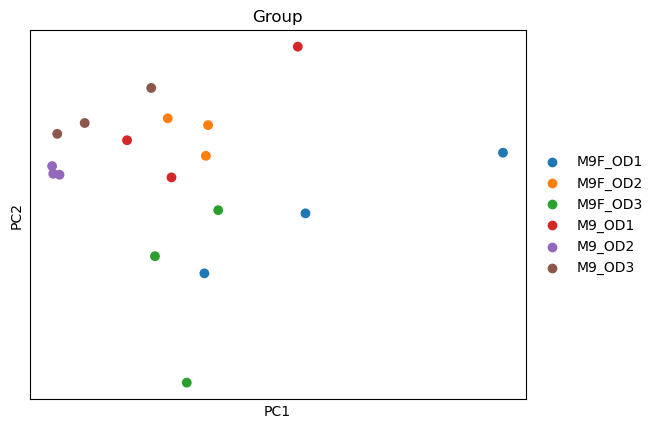

In [ ]:
sp.tl.pca(dds)
sp.pl.pca(dds, color="Group", size=200)

In [ ]:
stat_res = DeseqStats(dds, n_cpus=8, contrast=("Group", "M9F_OD2", "M9_OD2"))

In [ ]:
stat_res.summary()

Running Wald tests...


Log2 fold change & Wald test p-value: Group M9F_OD2 vs M9_OD2
                baseMean  log2FoldChange     lfcSE      stat    pvalue  \
gene_name                                                                
QLH64-00005  2467.487705       -0.043184  0.048065 -0.898454  0.368944   
QLH64-00010     0.045610       -1.957837  5.703738 -0.343255  0.731407   
QLH64-00015     0.051324       -1.957837  5.703734 -0.343255  0.731406   
QLH64-00020  3985.235064       -0.037087  0.045186 -0.820770  0.411777   
rrf_1           0.388499       -2.919644  2.683221 -1.088111  0.276546   
...                  ...             ...       ...       ...       ...   
QLH64-31225     4.347773       -0.830673  0.864030 -0.961394  0.336354   
recA_2          2.363294       -0.375132  1.257320 -0.298358  0.765430   
QLH64-31235     1.808419       -0.387930  1.361168 -0.284998  0.775645   
QLH64-31240     0.394615       -0.996052  2.755617 -0.361462  0.717754   
QLH64-31245     0.926046        0.946106  2.219284

... done in 0.69 seconds.



In [ ]:
de = stat_res.results_df

In [ ]:
de.sort_values("stat", ascending=False)

,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj
gene_name,,,,,,
QLH64-20765,18.126209,1.302823,0.497025,2.621242,0.008761,0.996101
QLH64-06930,41.528966,0.783852,0.315524,2.484284,0.012981,0.996101
QLH64-23785,18.763806,1.357884,0.553007,2.455457,0.014071,0.996101
QLH64-28005,86.630335,0.451891,0.195243,2.314508,0.020640,0.996101
rlmE,9.024096,2.394974,1.067441,2.243659,0.024854,0.996101
...,...,...,...,...,...,...
QLH64-19310,55.282285,-0.551735,0.215881,-2.555741,0.010596,0.996101
nuoH,34.881546,-0.699814,0.259551,-2.696254,0.007012,0.996101
QLH64-17530,2.857497,-2.977601,1.100793,-2.704961,0.006831,0.996101


pas de chose significative apres adj ; normal car peut de replica (faire plus de replic (speudo-repli))

In [ ]:
%pip install sanbomics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 7.0 MB/s eta 0:00:00a 0:00:01
Note: you may need to restart the kernel to use updated packages.


In [ ]:
from sanbomics.tools import id_map

In [ ]:
de

,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj
gene_name,,,,,,
QLH64-00005,2467.487705,-0.043184,0.048065,-0.898454,0.368944,0.996101
QLH64-00010,0.045610,-1.957837,5.703738,-0.343255,0.731407,0.996101
QLH64-00015,0.051324,-1.957837,5.703734,-0.343255,0.731406,0.996101
QLH64-00020,3985.235064,-0.037087,0.045186,-0.820770,0.411777,0.996101
rrf_1,0.388499,-2.919644,2.683221,-1.088111,0.276546,0.996101
...,...,...,...,...,...,...
QLH64-31225,4.347773,-0.830673,0.864030,-0.961394,0.336354,0.996101
recA_2,2.363294,-0.375132,1.257320,-0.298358,0.765430,0.996101
QLH64-31235,1.808419,-0.387930,1.361168,-0.284998,0.775645,0.996101


In [ ]:
res = de.sort_values("stat", ascending=False)

In [ ]:
res = res[res.baseMean >= 5]
res

,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj
gene_name,,,,,,
QLH64-20765,18.126209,1.302823,0.497025,2.621242,0.008761,0.996101
QLH64-06930,41.528966,0.783852,0.315524,2.484284,0.012981,0.996101
QLH64-23785,18.763806,1.357884,0.553007,2.455457,0.014071,0.996101
QLH64-28005,86.630335,0.451891,0.195243,2.314508,0.020640,0.996101
rlmE,9.024096,2.394974,1.067441,2.243659,0.024854,0.996101
...,...,...,...,...,...,...
QLH64-11740,11.207957,-1.120084,0.445496,-2.514240,0.011929,0.996101
QLH64-19310,55.282285,-0.551735,0.215881,-2.555741,0.010596,0.996101
nuoH,34.881546,-0.699814,0.259551,-2.696254,0.007012,0.996101


In [ ]:
sigs = res[(res.pvalue < 0.05) & (abs(res.log2FoldChange) > 0.5)]

In [ ]:
sigs

,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj
gene_name,,,,,,
QLH64-20765,18.126209,1.302823,0.497025,2.621242,0.008761,0.996101
QLH64-06930,41.528966,0.783852,0.315524,2.484284,0.012981,0.996101
QLH64-23785,18.763806,1.357884,0.553007,2.455457,0.014071,0.996101
rlmE,9.024096,2.394974,1.067441,2.243659,0.024854,0.996101
QLH64-17785,42.209117,0.702850,0.313304,2.243348,0.024874,0.996101
QLH64-04810,30.786419,0.900721,0.404801,2.225095,0.026075,0.996101
QLH64-14035,23.274972,0.969283,0.446707,2.169839,0.030019,0.996101
trpB,36.839026,0.683185,0.314869,2.169744,0.030026,0.996101
QLH64-29845,53.947767,0.542341,0.250732,2.163030,0.030539,0.996101


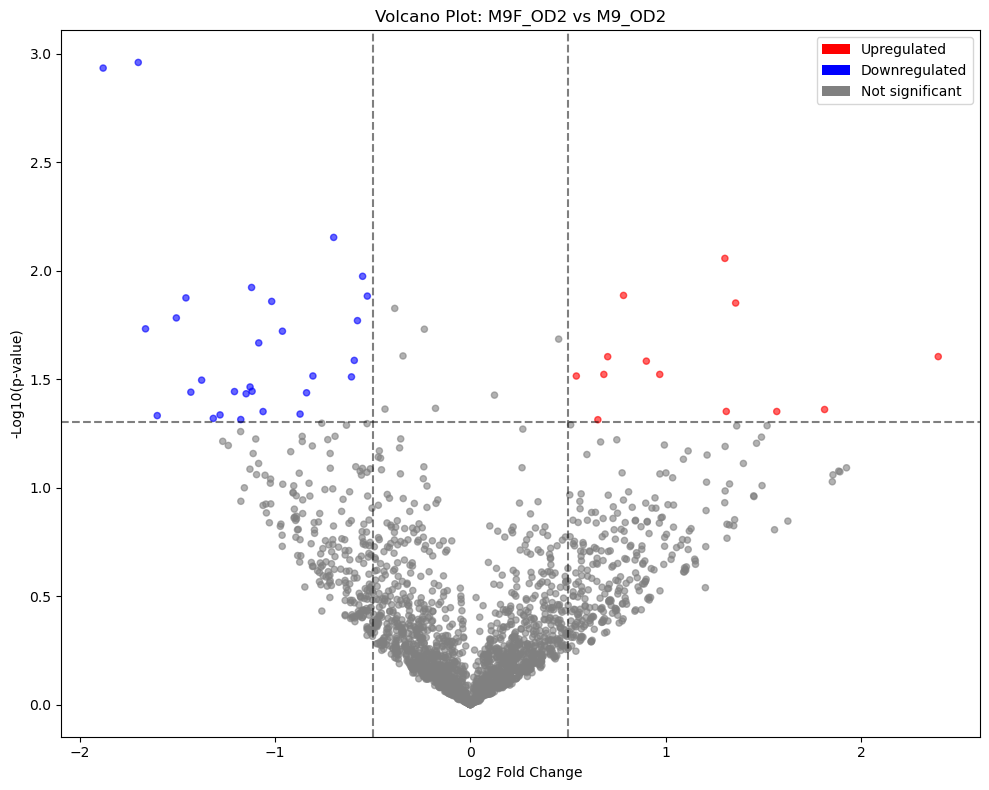

Significant genes (p < 0.05, |log2FC| > 0.5):
Upregulated: 13
Downregulated: 29
Total significant: 42


In [31]:
import matplotlib.pyplot as plt
import numpy as np


def volcano_plot(df, title="Volcano Plot"):
    """Create a volcano plot from DESeq2 results"""
    fig, ax = plt.subplots(figsize=(10, 8))

    # Calculate -log10(pvalue)
    df["-log10(pvalue)"] = -np.log10(df["pvalue"])

    # Define significance thresholds
    pval_threshold = 0.05
    lfc_threshold = 0.5

    # Color points based on significance
    colors = []
    for idx, row in df.iterrows():
        if (
            row["pvalue"] < pval_threshold
            and abs(row["log2FoldChange"]) > lfc_threshold
        ):
            if row["log2FoldChange"] > lfc_threshold:
                colors.append("red")  # Upregulated
            else:
                colors.append("blue")  # Downregulated
        else:
            colors.append("gray")  # Not significant

    # Create scatter plot
    scatter = ax.scatter(
        df["log2FoldChange"], df["-log10(pvalue)"], c=colors, alpha=0.6, s=20
    )

    # Add threshold lines
    ax.axhline(y=-np.log10(pval_threshold), color="black", linestyle="--", alpha=0.5)
    ax.axvline(x=lfc_threshold, color="black", linestyle="--", alpha=0.5)
    ax.axvline(x=-lfc_threshold, color="black", linestyle="--", alpha=0.5)

    # Labels and title
    ax.set_xlabel("Log2 Fold Change")
    ax.set_ylabel("-Log10(p-value)")
    ax.set_title(title)

    # Add legend
    from matplotlib.patches import Patch

    legend_elements = [
        Patch(facecolor="red", label="Upregulated"),
        Patch(facecolor="blue", label="Downregulated"),
        Patch(facecolor="gray", label="Not significant"),
    ]
    ax.legend(handles=legend_elements)

    plt.tight_layout()
    return fig


# Create volcano plot
fig = volcano_plot(res, "Volcano Plot: M9F_OD2 vs M9_OD2")
plt.show()

# Print summary statistics
n_up = len(sigs[sigs["log2FoldChange"] > 0])
n_down = len(sigs[sigs["log2FoldChange"] < 0])
print(f"Significant genes (p < 0.05, |log2FC| > 0.5):")
print(f"Upregulated: {n_up}")
print(f"Downregulated: {n_down}")
print(f"Total significant: {len(sigs)}")

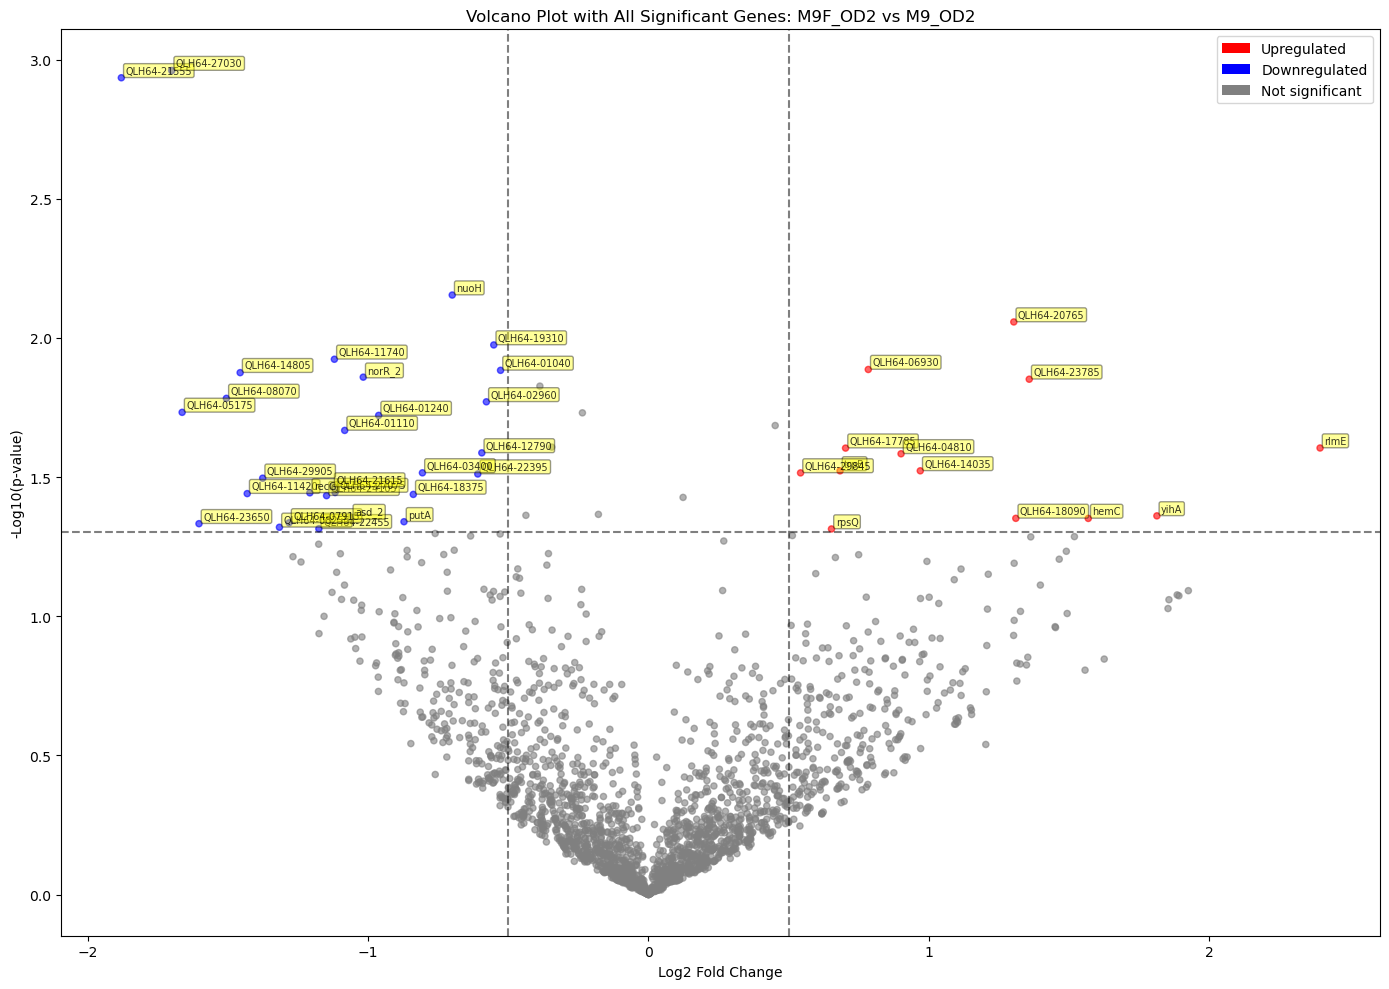

Significant genes (p < 0.05, |log2FC| > 0.5):
Upregulated: 13
Downregulated: 29
Total significant: 42


In [ ]:
# Volcano plot avec noms de TOUS les genes significatifs
def volcano_plot_all_labels(df, title="Volcano Plot with All Significant Gene Labels"):
    """Create a volcano plot with gene labels for ALL significant genes"""
    fig, ax = plt.subplots(figsize=(14, 10))

    # Calculate -log10(pvalue)
    df_plot = df.copy()
    df_plot["-log10(pvalue)"] = -np.log10(df_plot["pvalue"])

    # Define significance thresholds
    pval_threshold = 0.05
    lfc_threshold = 0.5

    # Color points based on significance
    colors = []
    for idx, row in df_plot.iterrows():
        if (
            row["pvalue"] < pval_threshold
            and abs(row["log2FoldChange"]) > lfc_threshold
        ):
            if row["log2FoldChange"] > lfc_threshold:
                colors.append("red")  # Upregulated
            else:
                colors.append("blue")  # Downregulated
        else:
            colors.append("gray")  # Not significant

    # Create scatter plot
    scatter = ax.scatter(
        df_plot["log2FoldChange"], df_plot["-log10(pvalue)"], c=colors, alpha=0.6, s=20
    )

    # Add threshold lines
    ax.axhline(y=-np.log10(pval_threshold), color="black", linestyle="--", alpha=0.5)
    ax.axvline(x=lfc_threshold, color="black", linestyle="--", alpha=0.5)
    ax.axvline(x=-lfc_threshold, color="black", linestyle="--", alpha=0.5)

    # Get ALL significant genes (same criteria as sigs variable)
    sig_genes_for_labels = df_plot[
        (df_plot["pvalue"] < pval_threshold)
        & (abs(df_plot["log2FoldChange"]) > lfc_threshold)
    ]

    # Add gene labels for ALL significant genes
    for gene_name, row in sig_genes_for_labels.iterrows():
        ax.annotate(
            gene_name,
            (row["log2FoldChange"], row["-log10(pvalue)"]),
            xytext=(3, 3),
            textcoords="offset points",
            fontsize=7,
            alpha=0.8,
            bbox=dict(boxstyle="round,pad=0.2", facecolor="yellow", alpha=0.4),
        )

    # Labels and title
    ax.set_xlabel("Log2 Fold Change")
    ax.set_ylabel("-Log10(p-value)")
    ax.set_title(title)

    # Add legend
    from matplotlib.patches import Patch

    legend_elements = [
        Patch(facecolor="red", label="Upregulated"),
        Patch(facecolor="blue", label="Downregulated"),
        Patch(facecolor="gray", label="Not significant"),
    ]
    ax.legend(handles=legend_elements)

    plt.tight_layout()
    return fig


# Create volcano plot with ALL significant gene labels
fig = volcano_plot_all_labels(
    res, "Volcano Plot with All Significant Genes: M9F_OD2 vs M9_OD2"
)
plt.show()

# Print summary statistics
n_up = len(sigs[sigs["log2FoldChange"] > 0])
n_down = len(sigs[sigs["log2FoldChange"] < 0])
print(f"Significant genes (p < 0.05, |log2FC| > 0.5):")
print(f"Upregulated: {n_up}")
print(f"Downregulated: {n_down}")
print(f"Total significant: {len(sigs)}")